In [1]:
library(e1071)
library(caret)
library(pROC)

Loading required package: ggplot2


Attaching package: ‘ggplot2’


The following object is masked from ‘package:e1071’:

    element


Loading required package: lattice

Type 'citation("pROC")' for a citation.


Attaching package: ‘pROC’


The following objects are masked from ‘package:stats’:

    cov, smooth, var




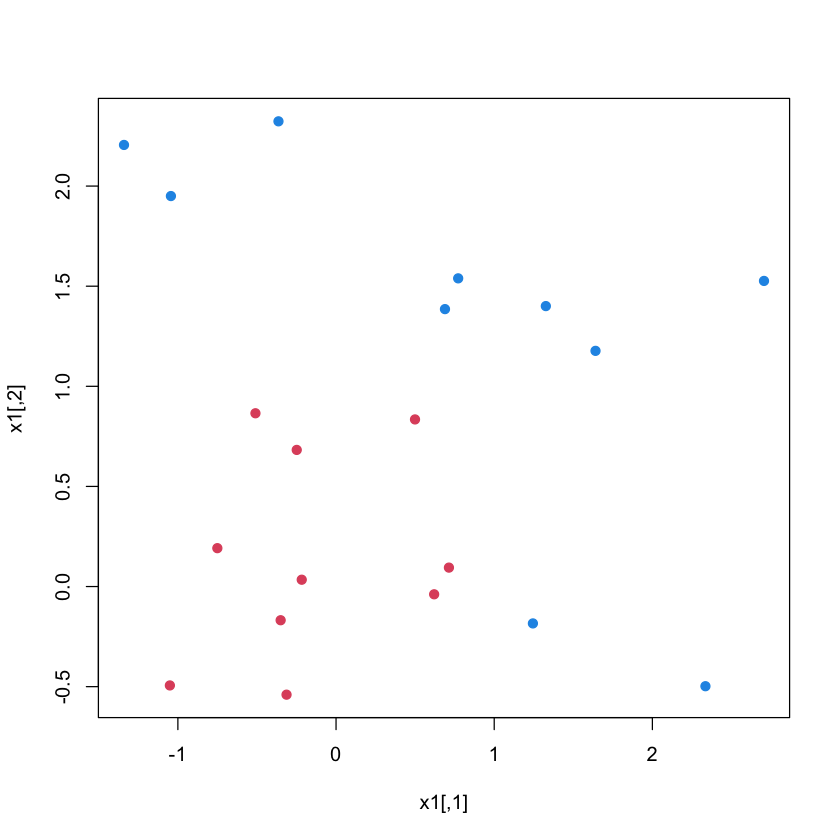

In [2]:
set.seed(10111)
x1 = matrix(rnorm(40), 20, 2)
y1 = rep(c(-1, 1), c(10, 10))
x1[y1 == 1, ] = x1[y1 == 1, ] + 1
plot(x1, col = y1 + 3, pch = 19)


Call:
svm(formula = y ~ ., data = dat1, kernel = "linear", cost = 10, scale = FALSE)


Parameters:
   SVM-Type:  C-classification 
 SVM-Kernel:  linear 
       cost:  10 

Number of Support Vectors:  6



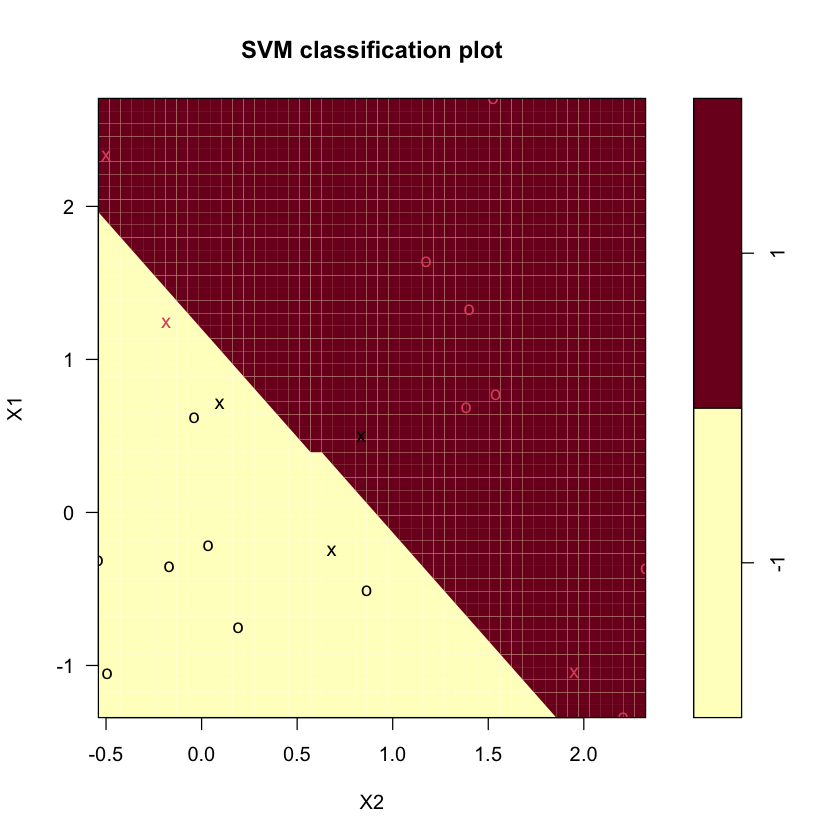

In [3]:
dat1 = data.frame(x1, y = as.factor(y1))
svm.linear = svm(y ~ ., data = dat1, kernel = "linear", cost = 10, scale = FALSE)
print(svm.linear)
plot(svm.linear, dat1)

In [4]:
rda = if (file.exists("../Data/ESL.mixture.rda")) "../Data/ESL.mixture.rda" else "Data/ESL.mixture.rda"
load(rda)
names(ESL.mixture)

[1] "x"        "y"        "xnew"     "prob"     "marginal" "px1"      "px2"     
[8] "means"

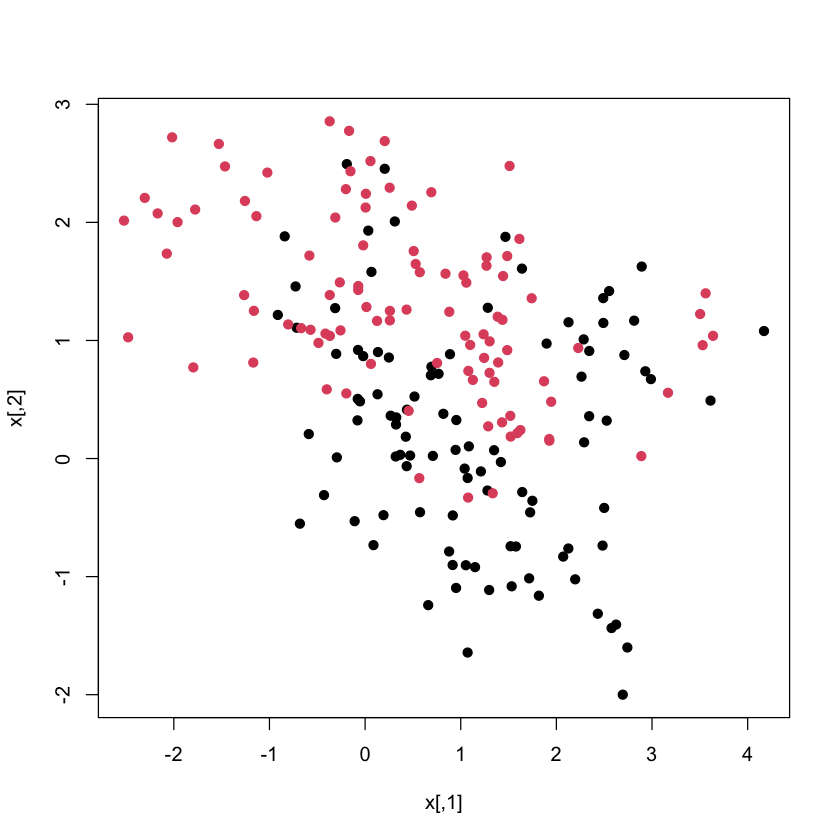

In [5]:
x = ESL.mixture$x
y = ESL.mixture$y
dat = data.frame(x, y = as.factor(y))
plot(x, col = y + 1, pch = 19)

In [6]:
set.seed(1)
prop.index <- createDataPartition(dat$y, p = 0.8, list = FALSE, times = 1)
train <- dat[prop.index, ]
test <- dat[-prop.index, ]
dim(train); dim(test)

[1] 160   3

[1] 40  3


Call:
svm(formula = y ~ ., data = train, kernel = "radial", cost = 1, gamma = 0.5)


Parameters:
   SVM-Type:  C-classification 
 SVM-Kernel:  radial 
       cost:  1 

Number of Support Vectors:  90



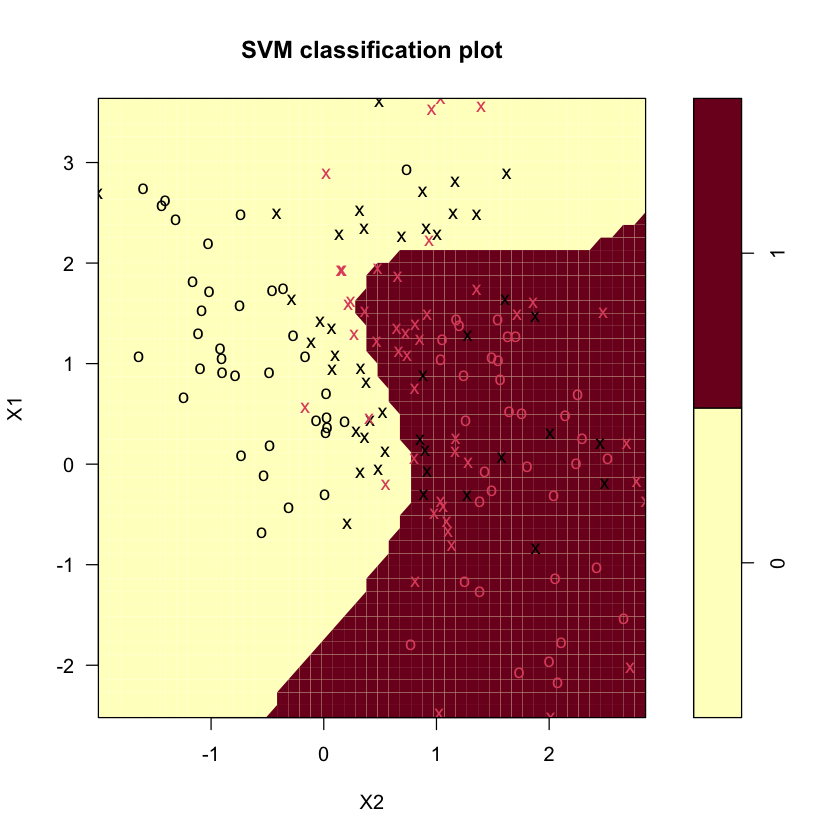

In [7]:
svm.fit <- svm(y ~ ., data = train, kernel = "radial", cost = 1, gamma = 0.5)
print(svm.fit)
plot(svm.fit, train)

In [8]:
pred.default = predict(svm.fit, test)
confusionMatrix(pred.default, test$y)

Confusion Matrix and Statistics

          Reference
Prediction  0  1
         0 10  6
         1 10 14
                                          
               Accuracy : 0.6             
                 95% CI : (0.4333, 0.7514)
    No Information Rate : 0.5             
    P-Value [Acc > NIR] : 0.1341          
                                          
                  Kappa : 0.2             
                                          
 Mcnemar's Test P-Value : 0.4533          
                                          
            Sensitivity : 0.5000          
            Specificity : 0.7000          
         Pos Pred Value : 0.6250          
         Neg Pred Value : 0.5833          
             Prevalence : 0.5000          
         Detection Rate : 0.2500          
   Detection Prevalence : 0.4000          
      Balanced Accuracy : 0.6000          
                                          
       'Positive' Class : 0               
                                    

In [9]:
set.seed(1)
tune.out <- tune(svm, y ~ ., data = train, kernel = "radial",
                 ranges = list(cost = 10^seq(-1, 3, 0.5),
                               gamma = c(0.05, 0.1, 0.25, 0.5, 1, 2, 4)),
                 tunecontrol = tune.control(cross = 10, nrepeat = 5))
tune.out$best.parameters
tune.out$best.performance

,cost,gamma
,<dbl>,<dbl>
49,3.162278,2


[1] 0.125


Call:
best.tune(METHOD = svm, train.x = y ~ ., data = train, ranges = list(cost = 10^seq(-1, 
    3, 0.5), gamma = c(0.05, 0.1, 0.25, 0.5, 1, 2, 4)), tunecontrol = tune.control(cross = 10, 
    nrepeat = 5), kernel = "radial")


Parameters:
   SVM-Type:  C-classification 
 SVM-Kernel:  radial 
       cost:  3.162278 

Number of Support Vectors:  81



Confusion Matrix and Statistics

          Reference
Prediction  0  1
         0 11  4
         1  9 16
                                          
               Accuracy : 0.675           
                 95% CI : (0.5087, 0.8143)
    No Information Rate : 0.5             
    P-Value [Acc > NIR] : 0.01924         
                                          
                  Kappa : 0.35            
                                          
 Mcnemar's Test P-Value : 0.26726         
                                          
            Sensitivity : 0.5500          
            Specificity : 0.8000          
         Pos Pred Value : 0.7333          
         Neg Pred Value : 0.6400          
             Prevalence : 0.5000          
         Detection Rate : 0.2750          
   Detection Prevalence : 0.3750          
      Balanced Accuracy : 0.6750          
                                          
       'Positive' Class : 0               
                                    

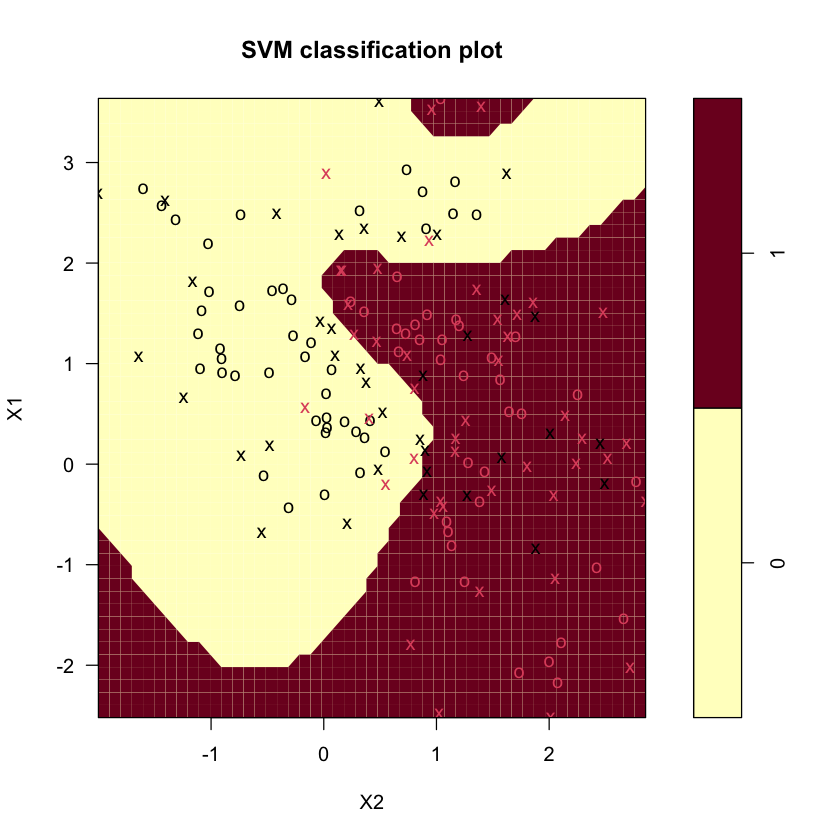

In [10]:
best.fit <- tune.out$best.model
print(best.fit)
plot(best.fit, train)
pred.best = predict(best.fit, test)
confusionMatrix(pred.best, test$y)

In [11]:
for (g in c(0.1, 1, 10)) for (cst in c(0.1, 1, 100)) {
  f = svm(y ~ ., data = train, kernel = "radial", cost = cst, gamma = g)
  cat(sprintf("cost = %6.1f  gamma = %5.1f  train acc = %.3f  test acc = %.3f\n", cst, g,
              mean(predict(f, train) == train$y), mean(predict(f, test) == test$y)))
}

cost =    0.1  gamma =   0.1  train acc = 0.762  test acc = 0.575
cost =    1.0  gamma =   0.1  train acc = 0.787  test acc = 0.600
cost =  100.0  gamma =   0.1  train acc = 0.819  test acc = 0.600
cost =    0.1  gamma =   1.0  train acc = 0.806  test acc = 0.525
cost =    1.0  gamma =   1.0  train acc = 0.863  test acc = 0.650
cost =  100.0  gamma =   1.0  train acc = 0.887  test acc = 0.750
cost =    0.1  gamma =  10.0  train acc = 0.906  test acc = 0.700
cost =    1.0  gamma =  10.0  train acc = 0.906  test acc = 0.700
cost =  100.0  gamma =  10.0  train acc = 0.994  test acc = 0.575


In [12]:
bayes.prob = sapply(1:nrow(test), function(k) {
  j = which.min((ESL.mixture$xnew[, 1] - test$X1[k])^2 + (ESL.mixture$xnew[, 2] - test$X2[k])^2)
  ESL.mixture$prob[j]
})
mean((bayes.prob > 0.5) == (test$y == "1"))
auc(roc(test$y, bayes.prob, levels = c("0", "1"), direction = "<"))

[1] 0.75

Area under the curve: 0.78

The default model (cost = 1, gamma = 0.5) gets 60% test accuracy. Repeated 10-fold CV (5 repeats) picked cost = 3.16, gamma = 2 (CV error 0.125), which raised test accuracy to 67.5%. Small cost and small gamma give a smooth boundary that underfits (about 55-60% test accuracy). Large cost with large gamma (cost = 100, gamma = 10) fits the training set almost perfectly (99.4%) but drops to 57.5% on test, which is overfitting. A larger gamma (around 2) worked best, with a moderate cost (around 1-10).

The data overlap a lot, so no classifier can do much better. The true Bayes classifier, built from the known probabilities in `ESL.mixture$prob`, gets only 75% accuracy and AUC 0.78 on this same test set. A few settings also hit 75% on the test set, but choosing them by test accuracy would be overfitting to the test set, so the CV choice is the honest one.

Area under the curve: 0.69

Area under the curve: 0.75

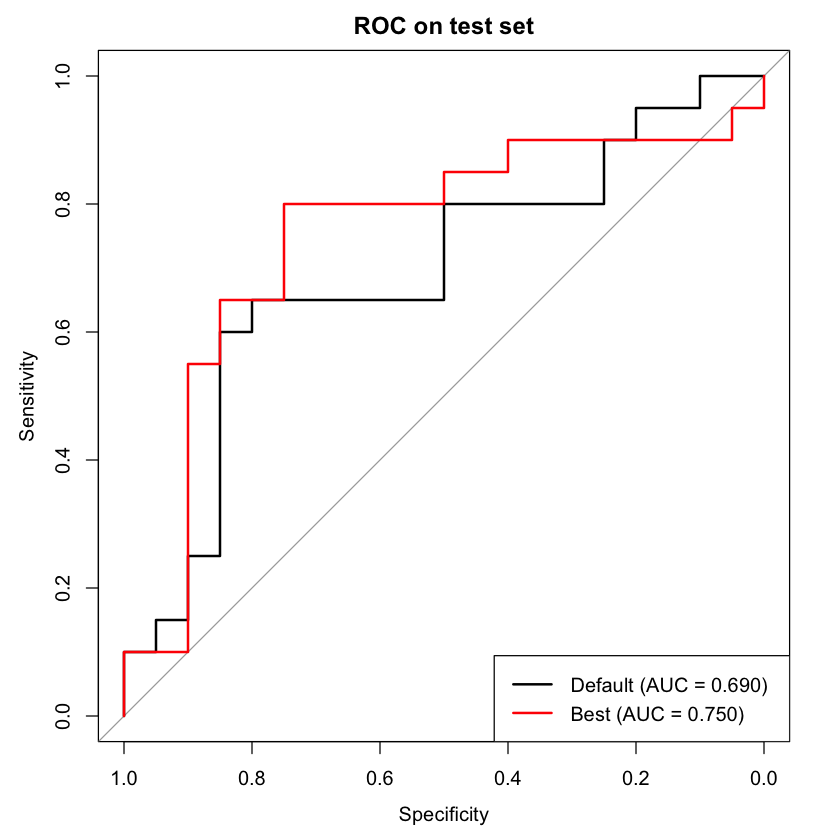

In [13]:
score = function(fit, newdata) {
  d = attributes(predict(fit, newdata, decision.values = TRUE))$decision.values
  if (colnames(d)[1] == "0/1") -d[, 1] else d[, 1]
}
roc.default = roc(test$y, score(svm.fit, test), levels = c("0", "1"), direction = "<")
roc.best    = roc(test$y, score(best.fit, test), levels = c("0", "1"), direction = "<")

plot(roc.default, col = "black", main = "ROC on test set")
plot(roc.best, col = "red", add = TRUE)
legend("bottomright",
       legend = c(sprintf("Default (AUC = %.3f)", auc(roc.default)),
                  sprintf("Best (AUC = %.3f)", auc(roc.best))),
       col = c("black", "red"), lwd = 2)
auc(roc.default); auc(roc.best)

Initial model AUC = 0.69 and best model AUC = 0.75. The tuned model ranks the test points noticeably better, and it is close to the Bayes classifier's AUC of 0.78, which is the best any model can do on this test set.